# 02 — Exploratory Data Analysis

First look at the digitised logbook: coverage, data gaps, how often and how
much the car was refuelled, and seasonality of use. Totals are shown for
**complete years only**; incomplete years (1999, 2021, 2026) are excluded
from absolute-sum charts but kept for rate metrics.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from galloper import io, cleaning, features, viz

viz.set_style()

# Build the analysis frame from raw (self-contained).
df = cleaning.clean(io.load_raw())
df = features.add_trip_features(df)
df = features.flag_price_outliers(df)
print(f"{len(df)} fill-ups | {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")


530 fill-ups | 1999-08-06 to 2026-09-04


## 1. Data quality overview

In [2]:
print("Rows:", len(df))
print("Missing odometer:", df['odometer_km'].isna().sum())
print("Missing litres :", df['litres'].isna().sum())
print("Missing date   :", df['date'].isna().sum())
print("Valid legs     :", int(df['leg_valid'].sum()))
print("Brands         :", df['brand'].nunique())
print("Total distance :", int(df['km_since_prev'].sum()), "km")
print("Total litres   :", round(df['litres'].sum(), 1))
print("Total spend    :", round(df['amount_eur'].sum(), 2), "EUR (nominal)")

Rows: 530
Missing odometer: 3
Missing litres : 5
Missing date   : 1
Valid legs     : 520
Brands         : 9
Total distance : 231521 km
Total litres   : 25526.6
Total spend    : 17720.45 EUR (nominal)


## 2. Fill-ups per year

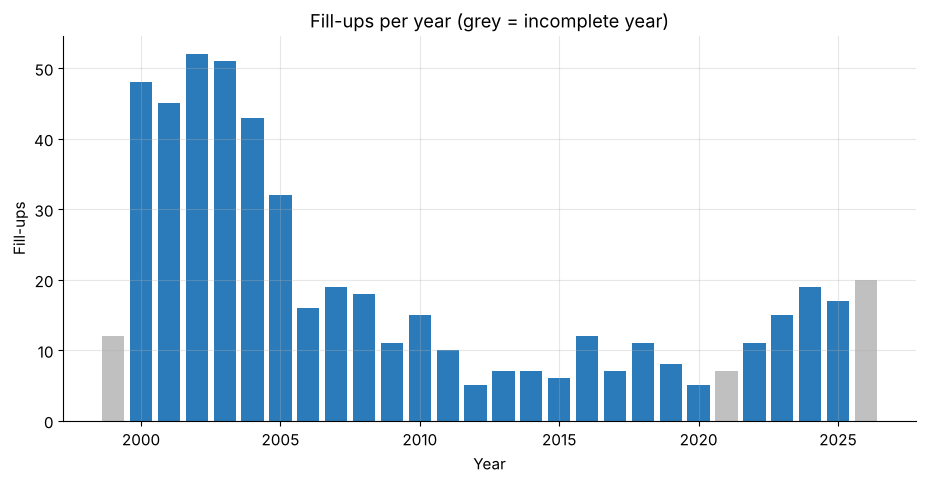

In [3]:
yearly = features.yearly_summary(df)
colors = np.where(yearly['is_complete'], '#2b7bba', '#c0c0c0')
fig, ax = plt.subplots()
ax.bar(yearly['year'].astype(int), yearly['fill_ups'], color=colors)
ax.set_title("Fill-ups per year (grey = incomplete year)")
ax.set_xlabel("Year"); ax.set_ylabel("Fill-ups")
viz.savefig(fig, "02_fillups_per_year"); plt.show()

## 3. Distance driven per year (complete years only)

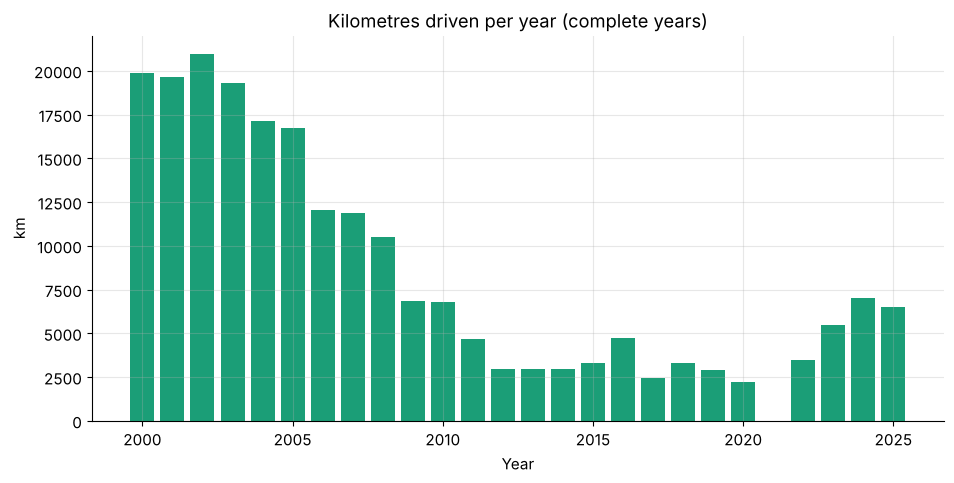

Mean km/year (complete): 8660


In [4]:
full = yearly[yearly['is_complete']]
fig, ax = plt.subplots()
ax.bar(full['year'].astype(int), full['km_travelled'], color='#1b9e77')
ax.set_title("Kilometres driven per year (complete years)")
ax.set_xlabel("Year"); ax.set_ylabel("km")
viz.savefig(fig, "02_km_per_year"); plt.show()

print("Mean km/year (complete):", int(full['km_travelled'].mean()))

## 4. Litres and spend per year (complete years)

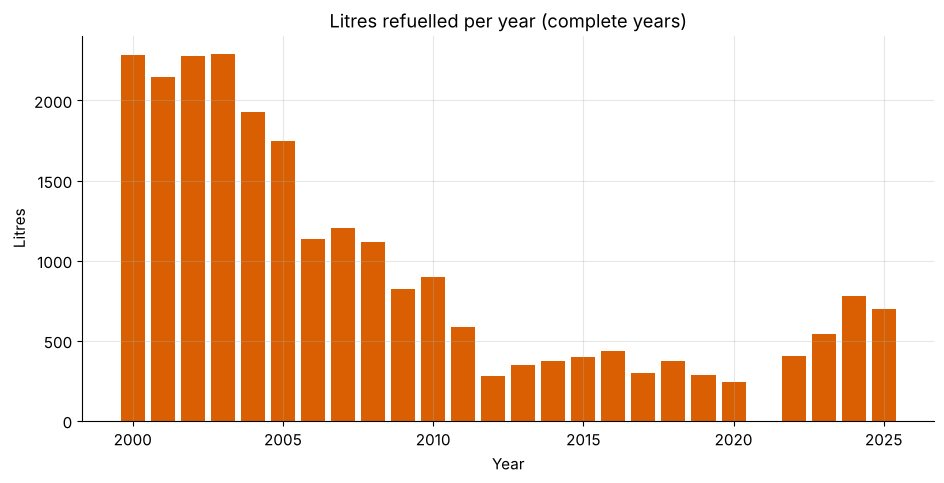

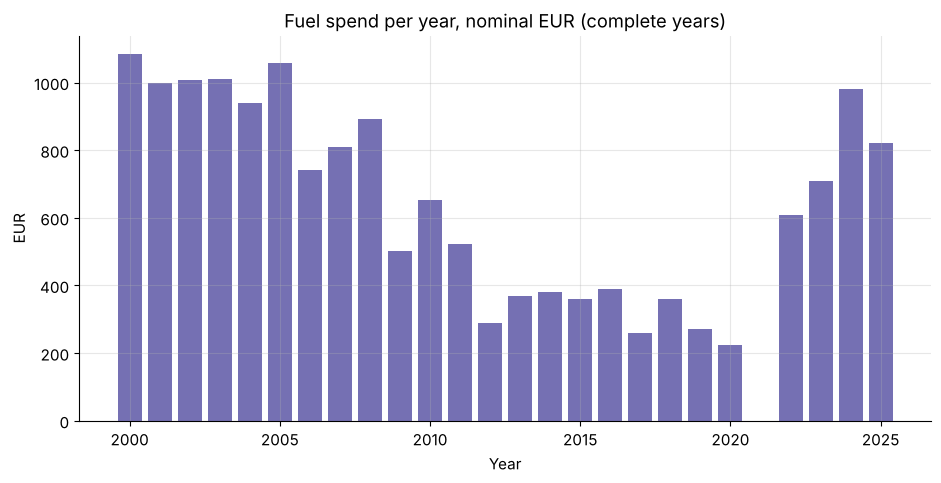

In [5]:
fig, ax = plt.subplots()
ax.bar(full['year'].astype(int), full['litres'], color='#d95f02')
ax.set_title("Litres refuelled per year (complete years)")
ax.set_xlabel("Year"); ax.set_ylabel("Litres")
viz.savefig(fig, "02_litres_per_year"); plt.show()

fig, ax = plt.subplots()
ax.bar(full['year'].astype(int), full['spend_eur'], color='#7570b3')
ax.set_title("Fuel spend per year, nominal EUR (complete years)")
ax.set_xlabel("Year"); ax.set_ylabel("EUR")
viz.savefig(fig, "02_spend_per_year"); plt.show()

## 5. Refuelling behaviour: gaps and fill sizes

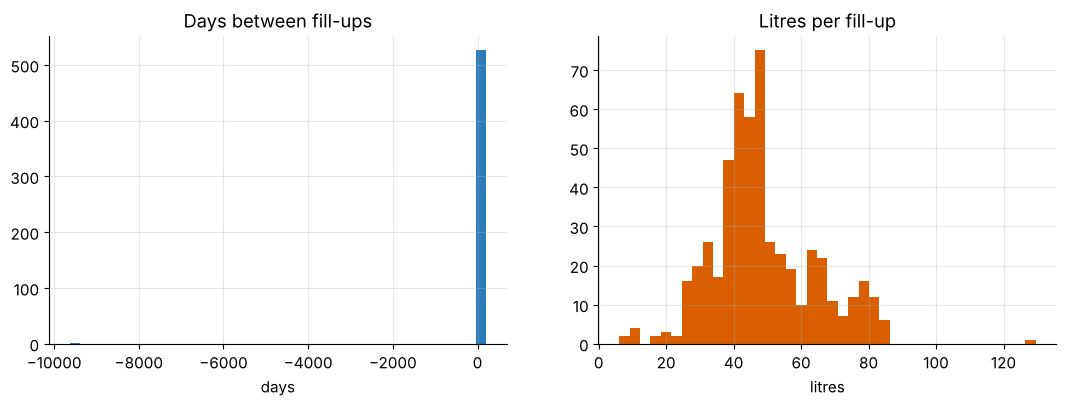

Median days between fills: 11.0
Median litres per fill  : 46.25


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df['days_since_prev'].dropna(), bins=40, color='#2b7bba')
axes[0].set_title("Days between fill-ups"); axes[0].set_xlabel("days")
axes[1].hist(df['litres'].dropna(), bins=40, color='#d95f02')
axes[1].set_title("Litres per fill-up"); axes[1].set_xlabel("litres")
viz.savefig(fig, "02_behaviour_hist"); plt.show()

print("Median days between fills:", df['days_since_prev'].median())
print("Median litres per fill  :", df['litres'].median())

## 6. Seasonality of use (year x month heatmap of distance)

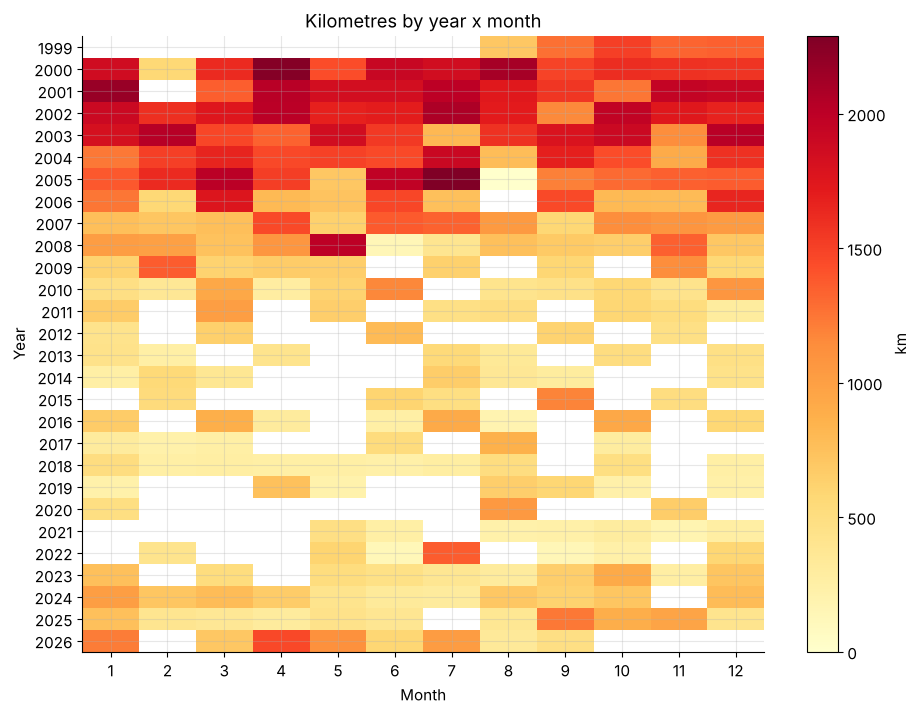

In [7]:
# Attribute each leg's distance to the month the fill-up closed it.
tmp = df.dropna(subset=['km_since_prev']).copy()
pivot = tmp.pivot_table(index='year', columns='month',
                        values='km_since_prev', aggfunc='sum')
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(pivot.values, aspect='auto', cmap='YlOrRd')
ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13))
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([int(y) for y in pivot.index])
ax.set_title("Kilometres by year x month")
ax.set_xlabel("Month"); ax.set_ylabel("Year")
fig.colorbar(im, ax=ax, label="km")
viz.savefig(fig, "02_seasonality_heatmap"); plt.show()

## 7. Fuel economy trend (rolling, aggregate)

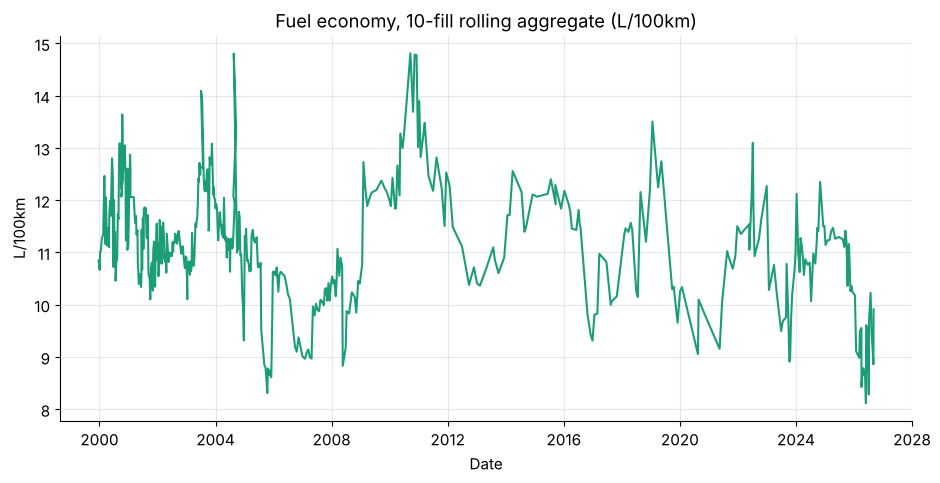

Lifetime aggregate L/100km: 11.03


In [8]:
roll = features.rolling_economy(df, window=10)
fig, ax = plt.subplots()
ax.plot(roll['date'], roll['l_per_100km_roll'], color='#1b9e77')
ax.set_title("Fuel economy, 10-fill rolling aggregate (L/100km)")
ax.set_xlabel("Date"); ax.set_ylabel("L/100km")
viz.savefig(fig, "02_economy_rolling"); plt.show()

print("Lifetime aggregate L/100km:",
      round(100*df['litres'].sum()/df['km_since_prev'].sum(), 2))